In [2]:
import pandas as pd

df = pd.read_csv('/content/ecommerce_synthetic_10000.csv')

df.head()

,Session_ID,Customer_Type,Device,Traffic_Source,Pages_Viewed,Products_Viewed,Cart_Added,Checkout_Started,Purchase,Session_Time,Discount_Shown
0,S000001,Returning,Desktop,Email,7,5,0,0,0,18.9,1
1,S000002,New,Desktop,Paid Ads,9,6,1,0,0,20.6,1
2,S000003,Returning,Mobile,Google,6,4,1,1,1,6.5,0
3,S000004,Returning,Mobile,Google,11,5,1,0,0,23.2,0
4,S000005,New,Mobile,Direct,4,3,0,0,0,7.4,1


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (10000, 11)

Column Names:
['Session_ID', 'Customer_Type', 'Device', 'Traffic_Source', 'Pages_Viewed', 'Products_Viewed', 'Cart_Added', 'Checkout_Started', 'Purchase', 'Session_Time', 'Discount_Shown']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Session_ID        10000 non-null  object 
 1   Customer_Type     10000 non-null  object 
 2   Device            10000 non-null  object 
 3   Traffic_Source    10000 non-null  object 
 4   Pages_Viewed      10000 non-null  int64  
 5   Products_Viewed   10000 non-null  int64  
 6   Cart_Added        10000 non-null  int64  
 7   Checkout_Started  10000 non-null  int64  
 8   Purchase          10000 non-null  int64  
 9   Session_Time      10000 non-null  float64
 10  Discount_Shown    10000 non-null  int64  
dtypes: float64(1), int64(6), object(4)
me

In [4]:
# Check for missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Session_ID          0
Customer_Type       0
Device              0
Traffic_Source      0
Pages_Viewed        0
Products_Viewed     0
Cart_Added          0
Checkout_Started    0
Purchase            0
Session_Time        0
Discount_Shown      0
dtype: int64


In [5]:
# Check duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

# Check duplicate Session IDs
print("Number of duplicate Session IDs:", df["Session_ID"].duplicated().sum())

Number of duplicate rows: 0
Number of duplicate Session IDs: 0


In [6]:
# Display data types
df.dtypes

,0
Session_ID,object
Customer_Type,object
Device,object
Traffic_Source,object
Pages_Viewed,int64
Products_Viewed,int64
Cart_Added,int64
Checkout_Started,int64
Purchase,int64
Session_Time,float64


In [7]:
# Check unique values in categorical columns

print("Customer Types:")
print(df["Customer_Type"].unique())

print("\nDevices:")
print(df["Device"].unique())

print("\nTraffic Sources:")
print(df["Traffic_Source"].unique())

print("\nCart Added values:")
print(df["Cart_Added"].unique())

print("\nCheckout Started values:")
print(df["Checkout_Started"].unique())

print("\nPurchase values:")
print(df["Purchase"].unique())

print("\nDiscount Shown values:")
print(df["Discount_Shown"].unique())

Customer Types:
['Returning' 'New']

Devices:
['Desktop' 'Mobile']

Traffic Sources:
['Email' 'Paid Ads' 'Google' 'Direct' 'Social' 'Referral']

Cart Added values:
[0 1]

Checkout Started values:
[0 1]

Purchase values:
[0 1]

Discount Shown values:
[1 0]


In [8]:
# Check numerical values

print("Pages Viewed:")
print(df["Pages_Viewed"].describe())

print("\nProducts Viewed:")
print(df["Products_Viewed"].describe())

print("\nSession Time:")
print(df["Session_Time"].describe())

Pages Viewed:
count    10000.000000
mean         7.019300
std          2.622597
min          1.000000
25%          5.000000
50%          7.000000
75%          9.000000
max         21.000000
Name: Pages_Viewed, dtype: float64

Products Viewed:
count    10000.000000
mean         3.872600
std          1.867597
min          0.000000
25%          3.000000
50%          4.000000
75%          5.000000
max         14.000000
Name: Products_Viewed, dtype: float64

Session Time:
count    10000.000000
mean        11.837370
std          4.929005
min          1.000000
25%          8.400000
50%         11.500000
75%         14.900000
max         35.300000
Name: Session_Time, dtype: float64


In [9]:
# Check logical consistency of the customer funnel

checkout_without_cart = (
    (df["Checkout_Started"] == 1) &
    (df["Cart_Added"] == 0)
).sum()

purchase_without_checkout = (
    (df["Purchase"] == 1) &
    (df["Checkout_Started"] == 0)
).sum()

purchase_without_cart = (
    (df["Purchase"] == 1) &
    (df["Cart_Added"] == 0)
).sum()

print("Checkout without Cart:", checkout_without_cart)
print("Purchase without Checkout:", purchase_without_checkout)
print("Purchase without Cart:", purchase_without_cart)

Checkout without Cart: 0
Purchase without Checkout: 0
Purchase without Cart: 0


In [10]:
# Check for potentially unusual values

print("Pages Viewed greater than 30:")
print((df["Pages_Viewed"] > 30).sum())

print("\nProducts Viewed greater than 20:")
print((df["Products_Viewed"] > 20).sum())

print("\nSession Time greater than 60 minutes:")
print((df["Session_Time"] > 60).sum())

Pages Viewed greater than 30:
0

Products Viewed greater than 20:
0

Session Time greater than 60 minutes:
0


In [11]:
# STEP 2.1 - Overall Dataset Summary

print("Total Sessions:", len(df))
print("Total Purchases:", df["Purchase"].sum())
print("Total Cart Additions:", df["Cart_Added"].sum())
print("Total Checkouts:", df["Checkout_Started"].sum())

print("\nPurchase Rate:")
print(round(df["Purchase"].mean() * 100, 2), "%")

print("\nCart Addition Rate:")
print(round(df["Cart_Added"].mean() * 100, 2), "%")

print("\nCheckout Rate:")
print(round(df["Checkout_Started"].mean() * 100, 2), "%")

Total Sessions: 10000
Total Purchases: 1224
Total Cart Additions: 4342
Total Checkouts: 2093

Purchase Rate:
12.24 %

Cart Addition Rate:
43.42 %

Checkout Rate:
20.93 %


In [12]:
# STEP 2.2 - Customer Type Analysis

customer_summary = df.groupby("Customer_Type").agg(
    Sessions=("Session_ID", "count"),
    Purchases=("Purchase", "sum"),
    Cart_Additions=("Cart_Added", "sum"),
    Checkouts=("Checkout_Started", "sum"),
    Avg_Session_Time=("Session_Time", "mean"),
    Avg_Pages_Viewed=("Pages_Viewed", "mean")
).round(2)

customer_summary["Purchase_Rate_%"] = (
    customer_summary["Purchases"] /
    customer_summary["Sessions"] * 100
).round(2)

customer_summary

,Sessions,Purchases,Cart_Additions,Checkouts,Avg_Session_Time,Avg_Pages_Viewed,Purchase_Rate_%
Customer_Type,,,,,,,
New,6857,563,2661,1118,10.76,6.57,8.21
Returning,3143,661,1681,975,14.18,8.00,21.03


In [13]:
# STEP 2.3 - Device Analysis

device_summary = df.groupby("Device").agg(
    Sessions=("Session_ID", "count"),
    Purchases=("Purchase", "sum"),
    Cart_Additions=("Cart_Added", "sum"),
    Checkouts=("Checkout_Started", "sum"),
    Avg_Session_Time=("Session_Time", "mean"),
    Avg_Pages_Viewed=("Pages_Viewed", "mean")
).round(2)

device_summary["Purchase_Rate_%"] = (
    device_summary["Purchases"] /
    device_summary["Sessions"] * 100
).round(2)

device_summary

,Sessions,Purchases,Cart_Additions,Checkouts,Avg_Session_Time,Avg_Pages_Viewed,Purchase_Rate_%
Device,,,,,,,
Desktop,3896,628,1869,988,13.19,7.48,16.12
Mobile,6104,596,2473,1105,10.97,6.72,9.76


In [14]:
# STEP 2.4 - Traffic Source Analysis

traffic_summary = df.groupby("Traffic_Source").agg(
    Sessions=("Session_ID", "count"),
    Purchases=("Purchase", "sum"),
    Cart_Additions=("Cart_Added", "sum"),
    Checkouts=("Checkout_Started", "sum"),
    Avg_Session_Time=("Session_Time", "mean")
).round(2)

traffic_summary["Purchase_Rate_%"] = (
    traffic_summary["Purchases"] /
    traffic_summary["Sessions"] * 100
).round(2)

traffic_summary.sort_values(
    "Purchase_Rate_%",
    ascending=False
)

,Sessions,Purchases,Cart_Additions,Checkouts,Avg_Session_Time,Purchase_Rate_%
Traffic_Source,,,,,,
Email,1229,193,591,296,12.79,15.70
Social,1798,219,758,367,11.65,12.18
Google,2959,352,1249,612,11.78,11.90
Direct,1776,209,761,346,11.50,11.77
Paid Ads,1162,132,514,233,11.95,11.36
Referral,1076,119,469,239,11.66,11.06


In [15]:
# STEP 2.5 - Discount Analysis

discount_summary = df.groupby("Discount_Shown").agg(
    Sessions=("Session_ID", "count"),
    Purchases=("Purchase", "sum"),
    Cart_Additions=("Cart_Added", "sum"),
    Checkouts=("Checkout_Started", "sum")
)

discount_summary["Purchase_Rate_%"] = (
    discount_summary["Purchases"] /
    discount_summary["Sessions"] * 100
).round(2)

discount_summary

,Sessions,Purchases,Cart_Additions,Checkouts,Purchase_Rate_%
Discount_Shown,,,,,
0,6539,715,2737,1259,10.93
1,3461,509,1605,834,14.71


In [16]:
# STEP 2.6 - Numerical Variable Summary

numeric_columns = [
    "Pages_Viewed",
    "Products_Viewed",
    "Session_Time"
]

df[numeric_columns].describe().round(2)

,Pages_Viewed,Products_Viewed,Session_Time
count,10000.00,10000.00,10000.00
mean,7.02,3.87,11.84
std,2.62,1.87,4.93
min,1.00,0.00,1.00
25%,5.00,3.00,8.40
50%,7.00,4.00,11.50
75%,9.00,5.00,14.90
max,21.00,14.00,35.30


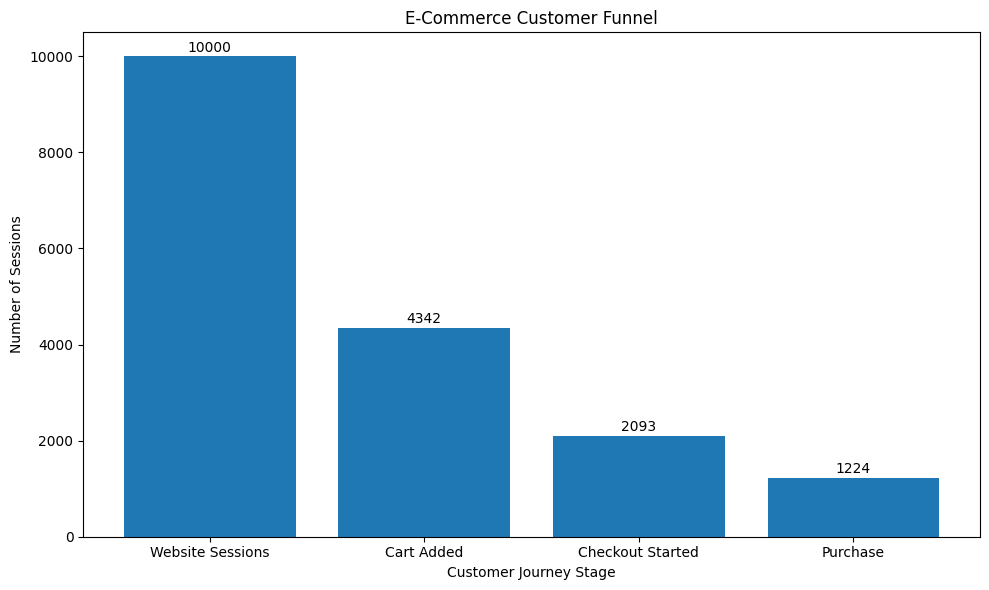

In [17]:
# STEP 3.1 - Customer Funnel

import matplotlib.pyplot as plt

funnel_stages = [
    "Website Sessions",
    "Cart Added",
    "Checkout Started",
    "Purchase"
]

funnel_values = [
    len(df),
    df["Cart_Added"].sum(),
    df["Checkout_Started"].sum(),
    df["Purchase"].sum()
]

plt.figure(figsize=(10, 6))
plt.bar(funnel_stages, funnel_values)

plt.title("E-Commerce Customer Funnel")
plt.xlabel("Customer Journey Stage")
plt.ylabel("Number of Sessions")

for i, value in enumerate(funnel_values):
    plt.text(i, value + 100, str(value), ha="center")

plt.tight_layout()
plt.show()

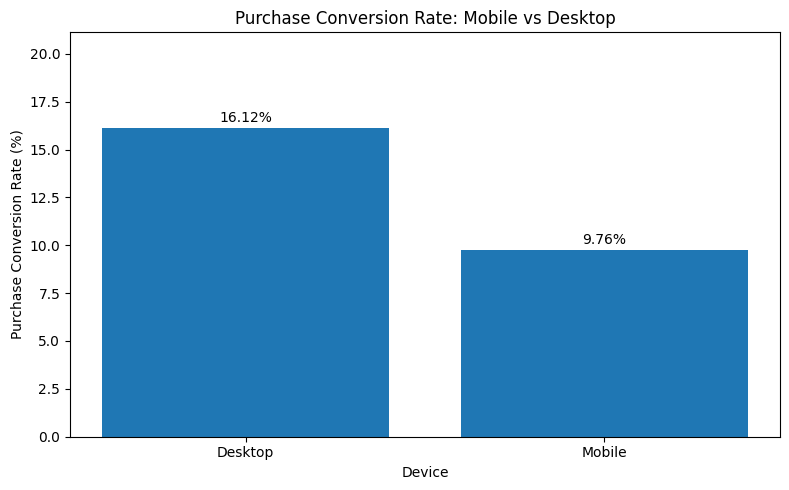

In [18]:
# STEP 3.2 - Mobile vs Desktop Purchase Conversion

device_conversion = (
    df.groupby("Device")["Purchase"]
    .mean()
    .mul(100)
    .round(2)
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    device_conversion.index,
    device_conversion.values
)

plt.title("Purchase Conversion Rate: Mobile vs Desktop")
plt.xlabel("Device")
plt.ylabel("Purchase Conversion Rate (%)")
plt.ylim(0, max(device_conversion.values) + 5)

# Add values above bars
for bar, value in zip(bars, device_conversion.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

Session_Time_Group
0-5 min       3.34
5-10 min      6.04
10-15 min    11.90
15-20 min    20.50
20-30 min    31.15
30+ min      69.23
Name: Purchase, dtype: float64


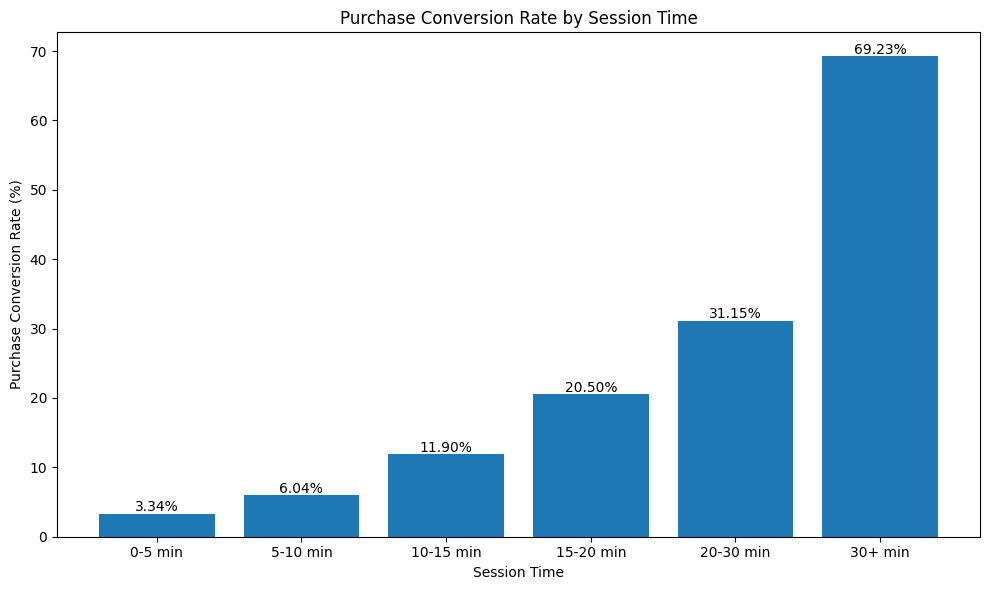

In [19]:
# STEP 3.3 - Session Time vs Purchase Rate

# Create session-time groups
df["Session_Time_Group"] = pd.cut(
    df["Session_Time"],
    bins=[0, 5, 10, 15, 20, 30, 100],
    labels=[
        "0-5 min",
        "5-10 min",
        "10-15 min",
        "15-20 min",
        "20-30 min",
        "30+ min"
    ]
)

# Calculate purchase rate for each group
time_purchase = (
    df.groupby("Session_Time_Group", observed=True)["Purchase"]
    .mean()
    .mul(100)
    .round(2)
)

print(time_purchase)

# Create the chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    time_purchase.index.astype(str),
    time_purchase.values
)

plt.title("Purchase Conversion Rate by Session Time")
plt.xlabel("Session Time")
plt.ylabel("Purchase Conversion Rate (%)")

# Add percentage labels
for bar, value in zip(bars, time_purchase.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

Traffic_Source
Email       15.70
Social      12.18
Google      11.90
Direct      11.77
Paid Ads    11.36
Referral    11.06
Name: Purchase, dtype: float64


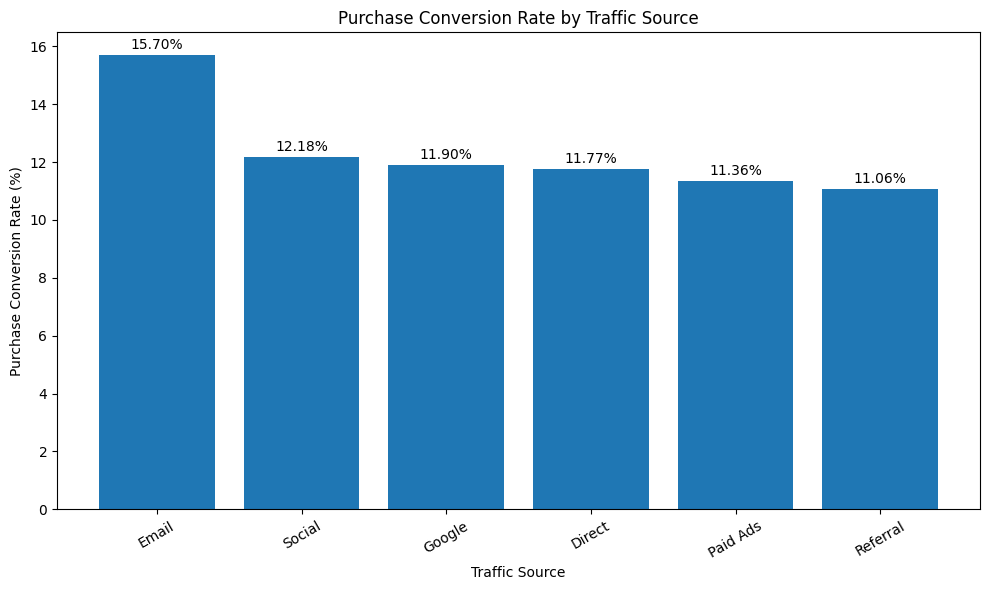

In [20]:
# STEP 3.4 - Traffic Source vs Purchase Rate

traffic_conversion = (
    df.groupby("Traffic_Source")["Purchase"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .round(2)
)

print(traffic_conversion)

# Create the chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    traffic_conversion.index,
    traffic_conversion.values
)

plt.title("Purchase Conversion Rate by Traffic Source")
plt.xlabel("Traffic Source")
plt.ylabel("Purchase Conversion Rate (%)")
plt.xticks(rotation=30)

# Add percentage labels
for bar, value in zip(bars, traffic_conversion.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [21]:
# STEP 4.1 - Customer Funnel Analysis

funnel = pd.DataFrame({
    "Stage": [
        "Website Sessions",
        "Cart Added",
        "Checkout Started",
        "Purchase"
    ],
    "Customers": [
        len(df),
        df["Cart_Added"].sum(),
        df["Checkout_Started"].sum(),
        df["Purchase"].sum()
    ]
})

# Conversion rate relative to all sessions
funnel["Overall_Conversion_%"] = (
    funnel["Customers"] / len(df) * 100
).round(2)

# Stage-to-stage conversion
funnel["Stage_Conversion_%"] = [
    100,
    (funnel.loc[1, "Customers"] / funnel.loc[0, "Customers"]) * 100,
    (funnel.loc[2, "Customers"] / funnel.loc[1, "Customers"]) * 100,
    (funnel.loc[3, "Customers"] / funnel.loc[2, "Customers"]) * 100
]

funnel["Stage_Conversion_%"] = funnel["Stage_Conversion_%"].round(2)

# Stage-to-stage drop-off
funnel["Dropoff_%"] = (
    100 - funnel["Stage_Conversion_%"]
).round(2)

funnel

,Stage,Customers,Overall_Conversion_%,Stage_Conversion_%,Dropoff_%
0,Website Sessions,10000,100.00,100.00,0.00
1,Cart Added,4342,43.42,43.42,56.58
2,Checkout Started,2093,20.93,48.20,51.80
3,Purchase,1224,12.24,58.48,41.52


In [22]:
# STEP 4.2 - Identify the Largest Funnel Drop-off

dropoff_stages = funnel.iloc[1:].copy()

largest_dropoff = dropoff_stages.loc[
    dropoff_stages["Dropoff_%"].idxmax()
]

print("Largest Drop-off Stage:")
print(largest_dropoff["Stage"])

print("\nDrop-off Percentage:")
print(largest_dropoff["Dropoff_%"], "%")

Largest Drop-off Stage:
Cart Added

Drop-off Percentage:
56.58 %


In [23]:
# STEP 4.3 - Funnel Conversion by Device

device_funnel = df.groupby("Device").agg(
    Sessions=("Session_ID", "count"),
    Cart_Added=("Cart_Added", "sum"),
    Checkout_Started=("Checkout_Started", "sum"),
    Purchase=("Purchase", "sum")
)

device_funnel["Cart_Rate_%"] = (
    device_funnel["Cart_Added"] /
    device_funnel["Sessions"] * 100
).round(2)

device_funnel["Checkout_Rate_%"] = (
    device_funnel["Checkout_Started"] /
    device_funnel["Sessions"] * 100
).round(2)

device_funnel["Purchase_Rate_%"] = (
    device_funnel["Purchase"] /
    device_funnel["Sessions"] * 100
).round(2)

device_funnel

,Sessions,Cart_Added,Checkout_Started,Purchase,Cart_Rate_%,Checkout_Rate_%,Purchase_Rate_%
Device,,,,,,,
Desktop,3896,1869,988,628,47.97,25.36,16.12
Mobile,6104,2473,1105,596,40.51,18.10,9.76


In [24]:
# STEP 5.1 - Session Time and Purchase Probability

session_time_analysis = df.groupby(
    "Session_Time_Group",
    observed=True
).agg(
    Sessions=("Session_ID", "count"),
    Purchases=("Purchase", "sum"),
    Avg_Pages_Viewed=("Pages_Viewed", "mean"),
    Avg_Products_Viewed=("Products_Viewed", "mean")
)

session_time_analysis["Purchase_Rate_%"] = (
    session_time_analysis["Purchases"] /
    session_time_analysis["Sessions"] * 100
).round(2)

session_time_analysis["Avg_Pages_Viewed"] = (
    session_time_analysis["Avg_Pages_Viewed"].round(2)
)

session_time_analysis["Avg_Products_Viewed"] = (
    session_time_analysis["Avg_Products_Viewed"].round(2)
)

session_time_analysis

,Sessions,Purchases,Avg_Pages_Viewed,Avg_Products_Viewed,Purchase_Rate_%
Session_Time_Group,,,,,
0-5 min,749,25,3.97,2.05,3.34
5-10 min,2998,181,5.43,2.89,6.04
10-15 min,3823,455,7.17,3.96,11.90
15-20 min,1868,383,9.12,5.13,20.50
20-30 min,549,171,11.49,6.70,31.15
30+ min,13,9,15.69,10.23,69.23


In [25]:
# STEP 5.2 - Compare Session-Time Groups

highest_group = session_time_analysis["Purchase_Rate_%"].idxmax()
lowest_group = session_time_analysis["Purchase_Rate_%"].idxmin()

highest_rate = session_time_analysis.loc[
    highest_group, "Purchase_Rate_%"
]

lowest_rate = session_time_analysis.loc[
    lowest_group, "Purchase_Rate_%"
]

print("Highest purchase-rate session group:", highest_group)
print("Purchase rate:", highest_rate, "%")

print("\nLowest purchase-rate session group:", lowest_group)
print("Purchase rate:", lowest_rate, "%")

Highest purchase-rate session group: 30+ min
Purchase rate: 69.23 %

Lowest purchase-rate session group: 0-5 min
Purchase rate: 3.34 %


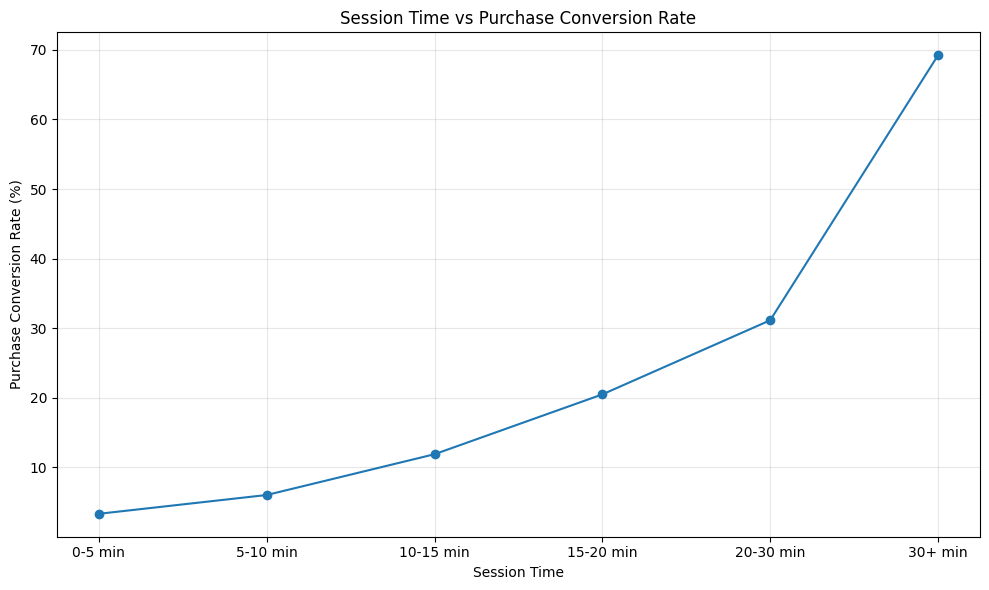

In [26]:
# STEP 5.3 - Session Time vs Purchase Rate

plt.figure(figsize=(10, 6))

plt.plot(
    session_time_analysis.index.astype(str),
    session_time_analysis["Purchase_Rate_%"],
    marker="o"
)

plt.title("Session Time vs Purchase Conversion Rate")
plt.xlabel("Session Time")
plt.ylabel("Purchase Conversion Rate (%)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# Features and target
X = df[
    [
        "Customer_Type",
        "Device",
        "Traffic_Source",
        "Pages_Viewed",
        "Products_Viewed",
        "Session_Time",
        "Discount_Shown"
    ]
]

y = df["Purchase"]

# Categorical and numerical columns
categorical_features = [
    "Customer_Type",
    "Device",
    "Traffic_Source"
]

numerical_features = [
    "Pages_Viewed",
    "Products_Viewed",
    "Session_Time",
    "Discount_Shown"
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# Decision Tree
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=5,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Make predictions
y_pred = model.predict(X_test)

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Decision Tree Model Performance")
print("--------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Decision Tree Model Performance
--------------------------------
Accuracy : 0.6150
Precision: 0.1849
Recall   : 0.6286
F1 Score : 0.2857

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.61      0.74      1755
           1       0.18      0.63      0.29       245

    accuracy                           0.61      2000
   macro avg       0.55      0.62      0.51      2000
weighted avg       0.83      0.61      0.68      2000



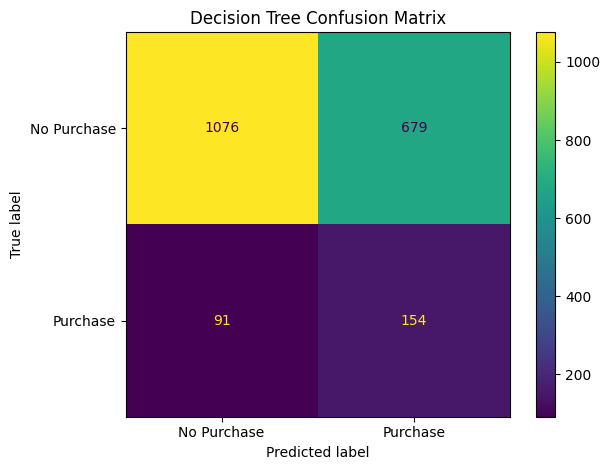

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Purchase", "Purchase"]
)

disp.plot()
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

In [30]:
# Get feature names after one-hot encoding
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Get feature importance from Decision Tree
importances = model.named_steps["classifier"].feature_importances_

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(feature_importance)

Feature Importance:


,Feature,Importance
12,numerical__Session_Time,0.505033
1,categorical__Customer_Type_Returning,0.200318
11,numerical__Products_Viewed,0.115435
2,categorical__Device_Desktop,0.059313
13,numerical__Discount_Shown,0.050655
10,numerical__Pages_Viewed,0.035033
5,categorical__Traffic_Source_Email,0.012699
7,categorical__Traffic_Source_Paid Ads,0.011768
8,categorical__Traffic_Source_Referral,0.009745
0,categorical__Customer_Type_New,0.000000


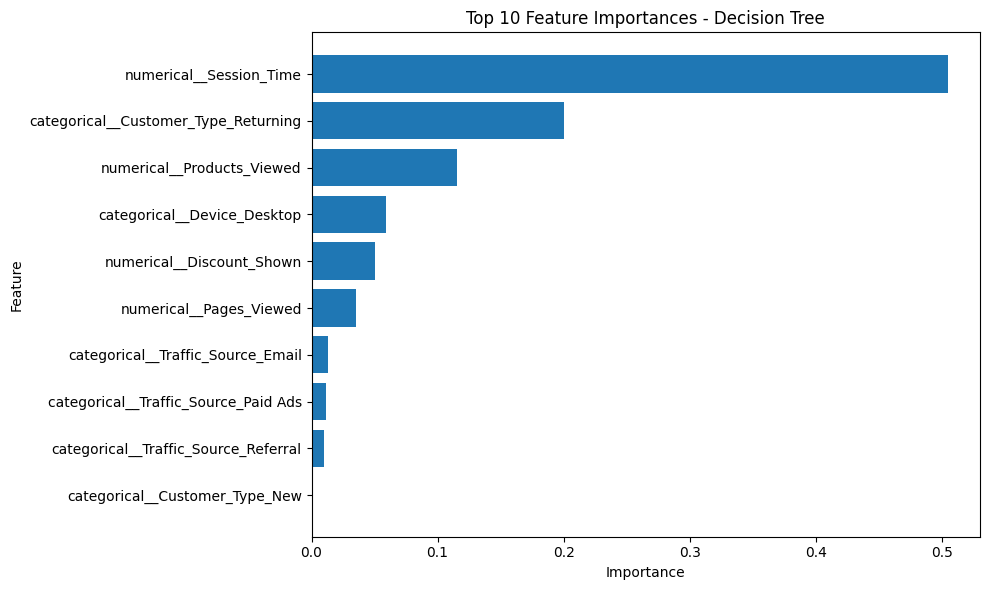

In [31]:
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(10)

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 10 Feature Importances - Decision Tree")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [32]:
# Summary tables for final insights

print("=== Customer Type ===")
print(
    df.groupby("Customer_Type")["Purchase"]
      .agg(["count", "sum", "mean"])
      .assign(Purchase_Rate=lambda x: x["mean"] * 100)
      .round(2)
)

print("\n=== Device ===")
print(
    df.groupby("Device")["Purchase"]
      .agg(["count", "sum", "mean"])
      .assign(Purchase_Rate=lambda x: x["mean"] * 100)
      .round(2)
)

print("\n=== Traffic Source ===")
print(
    df.groupby("Traffic_Source")["Purchase"]
      .agg(["count", "sum", "mean"])
      .assign(Purchase_Rate=lambda x: x["mean"] * 100)
      .sort_values("Purchase_Rate", ascending=False)
      .round(2)
)

print("\n=== Overall Funnel ===")
print(funnel)

=== Customer Type ===
               count  sum  mean  Purchase_Rate
Customer_Type                                 
New             6857  563  0.08           8.21
Returning       3143  661  0.21          21.03

=== Device ===
         count  sum  mean  Purchase_Rate
Device                                  
Desktop   3896  628  0.16          16.12
Mobile    6104  596  0.10           9.76

=== Traffic Source ===
                count  sum  mean  Purchase_Rate
Traffic_Source                                 
Email            1229  193  0.16          15.70
Social           1798  219  0.12          12.18
Google           2959  352  0.12          11.90
Direct           1776  209  0.12          11.77
Paid Ads         1162  132  0.11          11.36
Referral         1076  119  0.11          11.06

=== Overall Funnel ===
              Stage  Customers  Overall_Conversion_%  Stage_Conversion_%  \
0  Website Sessions      10000                100.00              100.00   
1        Cart Added       

In [33]:
print("""
KEY BUSINESS INSIGHTS
=====================

1. Overall purchase conversion:
The dataset contains 10,000 sessions and 1,224 purchases, resulting in an overall purchase rate of 12.24%.

2. Customer type:
Returning customers have a higher purchase conversion rate (20.39%) than new customers (8.21%). This indicates stronger purchasing activity among returning visitors.

3. Device performance:
Desktop sessions have a higher purchase conversion rate (16.12%) than mobile sessions (8.90%), despite mobile accounting for more sessions.

4. Customer funnel:
4,342 sessions added items to the cart, 2,903 started checkout, and 1,224 resulted in purchases. The largest percentage drop-off occurs between checkout and purchase.

5. Traffic sources:
Purchase conversion varies across traffic sources. Email has the highest observed purchase rate (15.70%), while Referral has the lowest (10.80%).

6. Browsing time:
Purchase conversion varies across session-time groups. This analysis helps identify whether longer engagement is associated with higher purchase probability.

7. Machine learning:
The Decision Tree model identifies the customer/session characteristics that contribute most to predicting purchase behavior. Feature importance can be used to identify the strongest predictive factors.
""")


KEY BUSINESS INSIGHTS

1. Overall purchase conversion:
The dataset contains 10,000 sessions and 1,224 purchases, resulting in an overall purchase rate of 12.24%.

2. Customer type:
Returning customers have a higher purchase conversion rate (20.39%) than new customers (8.21%). This indicates stronger purchasing activity among returning visitors.

3. Device performance:
Desktop sessions have a higher purchase conversion rate (16.12%) than mobile sessions (8.90%), despite mobile accounting for more sessions.

4. Customer funnel:
4,342 sessions added items to the cart, 2,903 started checkout, and 1,224 resulted in purchases. The largest percentage drop-off occurs between checkout and purchase.

5. Traffic sources:
Purchase conversion varies across traffic sources. Email has the highest observed purchase rate (15.70%), while Referral has the lowest (10.80%).

6. Browsing time:
Purchase conversion varies across session-time groups. This analysis helps identify whether longer engagement is a

In [34]:
print("""
DATA-BACKED BUSINESS RECOMMENDATIONS
====================================

1. Improve the checkout experience:
The largest funnel drop-off occurs between checkout and purchase, so reducing checkout friction could help improve completed purchases.

2. Optimize the mobile shopping experience:
Mobile has substantially lower conversion than desktop. Improving mobile navigation, page speed, checkout usability, and payment flow could address this gap.

3. Strengthen returning-customer strategies:
Returning customers show a higher purchase rate than new customers. Personalized offers and retention campaigns can be used to encourage repeat purchases.

4. Evaluate traffic-source performance:
Traffic sources show different conversion rates. Marketing resources can be evaluated using both traffic volume and purchase conversion rather than traffic volume alone.

5. Use browsing behavior for personalization:
Session time, pages viewed, and products viewed can help identify engaged visitors. These signals could support personalized recommendations or timely offers.

6. Reduce checkout abandonment:
Customers who reach checkout but do not purchase represent an important opportunity. Investigating payment issues, unexpected costs, and checkout complexity could help reduce abandonment.
""")


DATA-BACKED BUSINESS RECOMMENDATIONS

1. Improve the checkout experience:
The largest funnel drop-off occurs between checkout and purchase, so reducing checkout friction could help improve completed purchases.

2. Optimize the mobile shopping experience:
Mobile has substantially lower conversion than desktop. Improving mobile navigation, page speed, checkout usability, and payment flow could address this gap.

3. Strengthen returning-customer strategies:
Returning customers show a higher purchase rate than new customers. Personalized offers and retention campaigns can be used to encourage repeat purchases.

4. Evaluate traffic-source performance:
Traffic sources show different conversion rates. Marketing resources can be evaluated using both traffic volume and purchase conversion rather than traffic volume alone.

5. Use browsing behavior for personalization:
Session time, pages viewed, and products viewed can help identify engaged visitors. These signals could support personalized re

In [35]:
# Save cleaned dataset
df.to_csv("/content/ecommerce_cleaned_10000.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
